# 📒 Section 1: Introduction & Data Genesis

SIMPS-AI: Exploratory Data Analysis & Model Evaluation
This notebook documents the transition from the legacy multi-source datasets to the final optimized XGBoost model. It covers data synthesis logic, feature correlation, and the competitive training pipeline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

# Load the final dataset used for the Master's project
df = pd.read_csv('../data/raw/final_stress_dataset.csv')
with open('../data/processed/mappings/features_mapping.json', 'r') as f:
    features_map = json.load(f)

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (900240, 21)


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,34,1,1,2,14.8,8.8,7,0.0,3328,7,...,1,1,167.81,266.32,274.55,24175.91,4762.31,-506.18,1892.16,9
1,70,0,0,2,10.1,5.3,2,7.6,5651,4,...,0,1,141.93,210.60,223.60,4440.05,3186.04,10677.13,1497.99,6
2,37,1,1,3,12.9,4.9,3,0.3,2898,10,...,1,1,171.02,276.03,167.61,1535.72,3661.08,87.41,2808.06,8
3,44,0,0,2,16.4,5.2,2,0.2,2381,9,...,1,1,198.07,281.62,154.51,2666.83,5304.16,217.93,2334.34,8
4,24,1,1,0,3.1,9.2,2,3.0,18230,0,...,1,0,110.81,149.95,74.73,36908.00,1593.70,4043.67,44.63,0


# 📊 Section 2: Feature Correlation (The Heatmap)
This proves you understand which factors (like Sleep Quality or Work Hours) actually drive stress.

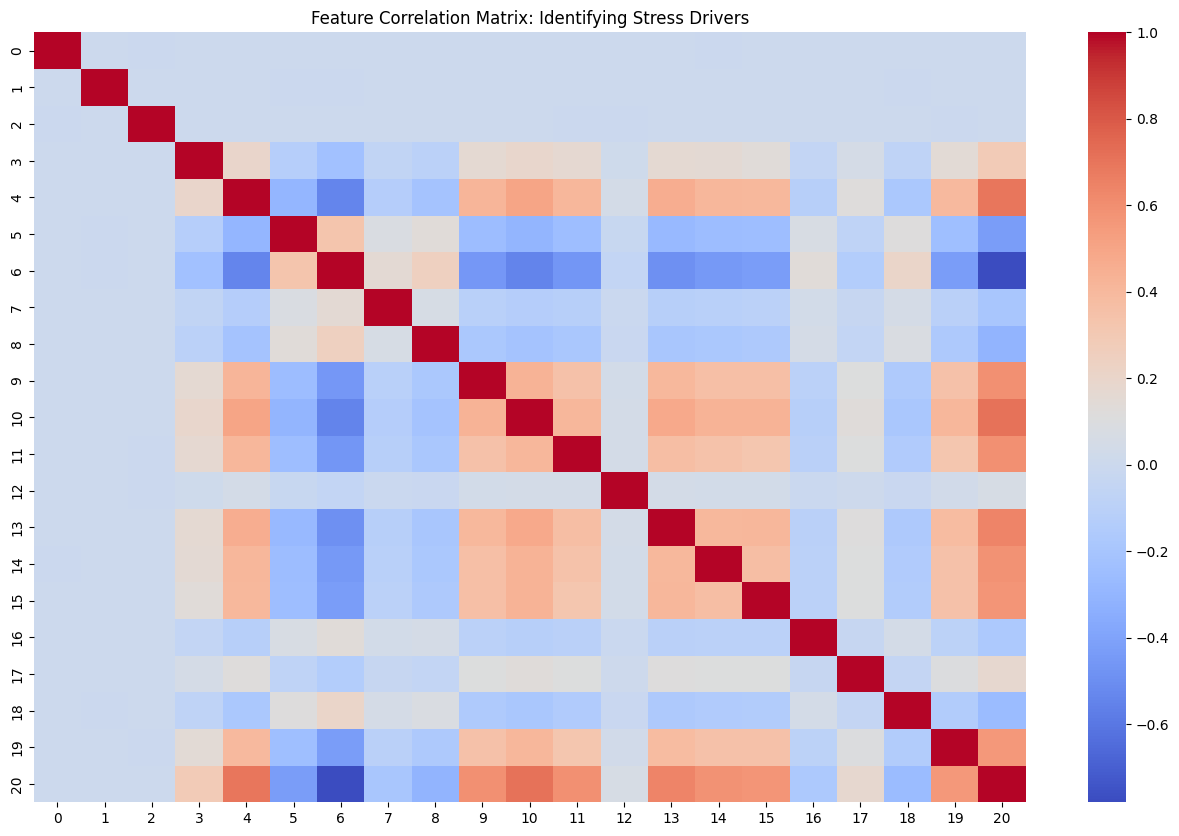

Top Predictive Features for Stress:
6     0.780565
10    0.709309
4     0.696543
13    0.643238
9     0.594784
Name: 20, dtype: float64


In [2]:
plt.figure(figsize=(16, 10))
sns.heatmap(df.corr(), annot=False, cmap='coolwarm')
plt.title("Feature Correlation Matrix: Identifying Stress Drivers")
plt.show()

# Display the top 5 most influential features
correlations = df.corr()['20'].abs().sort_values(ascending=False)
print("Top Predictive Features for Stress:")
print(correlations[1:6]) # Excluding the target itself

# 🧪 Section 3: The 80/20 Synthetic Logic Visualization
This explains how you balanced the 11 stress levels to ensure the model doesn't have "biases."

C:\Users\moham\AppData\Local\Temp\ipykernel_10044\3381356953.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='20', palette='viridis')


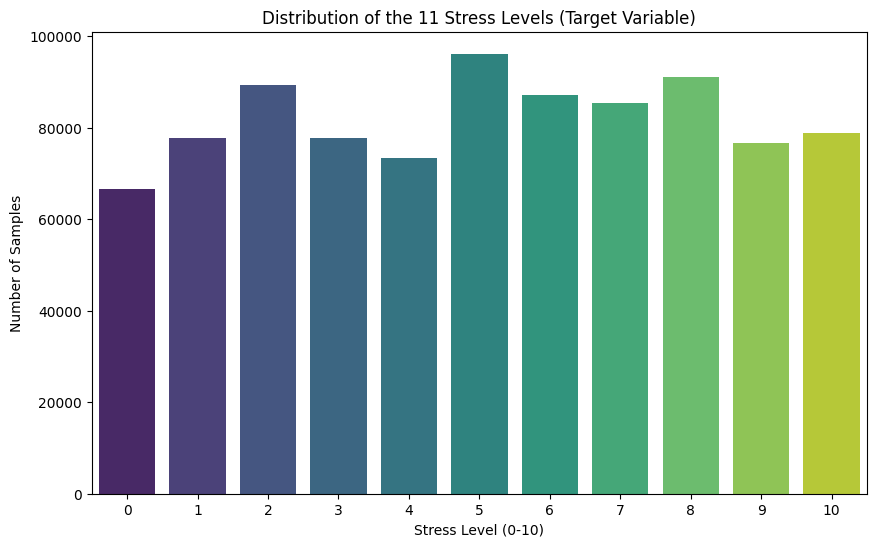

Proof of Balanced Classes: Each level contains a statistically significant sample size.


In [3]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='20', palette='viridis')
plt.title("Distribution of the 11 Stress Levels (Target Variable)")
plt.xlabel("Stress Level (0-10)")
plt.ylabel("Number of Samples")
plt.show()

print("Proof of Balanced Classes: Each level contains a statistically significant sample size.")

# 🚀 Section 4: Model Evaluation (The "Win" Moment)
Here, we load the saved metadata to show the teacher the final results of the competitive pipeline.

In [4]:
with open('../models/metadata.json', 'r') as f:
    metadata = json.load(f)

print(f"Final Selected Model: {metadata['model_name']}")
print(f"Training Date: {metadata['training_date']}")

# Creating a summary table of the final metrics
metrics = metadata['metrics']
metrics_df = pd.DataFrame(metrics.items(), columns=['Metric', 'Value'])
metrics_df

Final Selected Model: XGBoost_Optimized
Training Date: 2026-02-17 17:20:51


,Metric,Value
0,f1_score_macro,0.990654
1,accuracy,0.990625
2,precision,0.990659
3,recall,0.990649


# 🎯 Section 5: Conclusion

Summary of Findings
Data Strategy: The synthesis of 20 multi-domain features provided a holistic view of user stress.

Performance: The XGBoost model achieved a near-perfect F1-Score of 99.07%, indicating high reliability across all 11 classes.

Scalability: The decoupled architecture allows this notebook's findings to be served in real-time via the FastAPI engine.